In [24]:
import pandas as pd

df = pd.read_csv('/content/IPL_Matches_With_Mixed_Variable.csv')

In [25]:
df.head()

,date,season,city,venue,team1,team2,toss_winner,toss_decision,team1_runs,team1_wickets,...,match_referee,umpire1,umpire2,tv_umpire,reserve_umpire,overs_limit,team1_players,team2_players,player_of_match_jersey,playername_jerseyno
0,26-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Chennai Super Kings,Kolkata Knight Riders,Kolkata Knight Riders,field,131.0,5,...,M Nayyar,AK Chaudhary,Nitin Menon,VK Sharma,Chirra Ravikanthreddy,20,"RD Gaikwad, DP Conway, RV Uthappa, AT Rayudu, ...","AM Rahane, VR Iyer, N Rana, SS Iyer, SW Billin...",99.0,UT Yadav_99
1,27-03-2022,2022,Mumbai,"Brabourne Stadium, Mumbai",Mumbai Indians,Delhi Capitals,Delhi Capitals,field,177.0,5,...,Prakash Bhatt,RJ Tucker,HAS Khalid,J Madanagopal,N Pandit,20,"RG Sharma, Ishan Kishan, Anmolpreet Singh, Til...","PP Shaw, TL Seifert, Mandeep Singh, RR Pant, L...",52.0,Kuldeep Yadav_52
2,27-03-2022,2022,Mumbai,"Dr DY Patil Sports Academy, Mumbai",Royal Challengers Bangalore,Punjab Kings,Punjab Kings,field,205.0,2,...,M Nayyar,Nitin Menon,YC Barde,AK Chaudhary,R Pandit,20,"F du Plessis, Anuj Rawat, V Kohli, KD Karthik,...","MA Agarwal, S Dhawan, PBB Rajapaksa, LS Living...",38.0,OF Smith_38
3,28-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Lucknow Super Giants,Gujarat Titans,Gujarat Titans,field,158.0,6,...,DS Manohar,PG Pathak,VK Sharma,RJ Tucker,GR Sadashiv Iyer,20,"KL Rahul, Q de Kock, E Lewis, MK Pandey, DJ Ho...","Shubman Gill, MS Wade, V Shankar, HH Pandya, D...",70.0,Mohammed Shami_70
4,29-03-2022,2022,Pune,"Maharashtra Cricket Association Stadium, Pune",Rajasthan Royals,Sunrisers Hyderabad,Sunrisers Hyderabad,field,210.0,6,...,Shakti Singh,BNJ Oxenford,UV Gandhe,KN Ananthapadmanabhan,MV Saidharshan Kumar,20,"JC Buttler, YBK Jaiswal, SV Samson, D Padikkal...","KS Williamson, Abhishek Sharma, RA Tripathi, N...",78.0,SV Samson_78


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367 entries, 0 to 366
Data columns (total 27 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    367 non-null    object 
 1   season                  367 non-null    int64  
 2   city                    367 non-null    object 
 3   venue                   367 non-null    object 
 4   team1                   367 non-null    object 
 5   team2                   367 non-null    object 
 6   toss_winner             367 non-null    object 
 7   toss_decision           367 non-null    object 
 8   team1_runs              358 non-null    float64
 9   team1_wickets           367 non-null    int64  
 10  team2_runs              358 non-null    float64
 11  team2_wickets           367 non-null    int64  
 12  winner                  354 non-null    object 
 13  result_type             367 non-null    object 
 14  win_by_runs             367 non-null    in

In [27]:
df['player_of_match_jersey']=df['player_of_match_jersey'].astype('Int64')


In [28]:
df['playername_jerseyno']

,playername_jerseyno
0,UT Yadav_99
1,Kuldeep Yadav_52
2,OF Smith_38
3,Mohammed Shami_70
4,SV Samson_78
...,...
362,Kuldeep Yadav_52
363,RM Patidar_90
364,V Suryavanshi_3
365,Shubman Gill_92


In [29]:
df[['player_name','jersey_no']]=df['playername_jerseyno'].str.rsplit(n=1,expand=True)
df.drop(columns=['player_of_match_jersey'],inplace=True)
df[['playername_jerseyno','player_name','jersey_no']].head(10)

,playername_jerseyno,player_name,jersey_no
0,UT Yadav_99,UT,Yadav_99
1,Kuldeep Yadav_52,Kuldeep,Yadav_52
2,OF Smith_38,OF,Smith_38
3,Mohammed Shami_70,Mohammed,Shami_70
4,SV Samson_78,SV,Samson_78
5,PWH de Silva_24,PWH de,Silva_24
6,E Lewis_69,E,Lewis_69
7,UT Yadav_99,UT,Yadav_99
8,LH Ferguson_3,LH,Ferguson_3
9,JC Buttler_77,JC,Buttler_77


# Handling Date, Time and Feature Splitting

In [30]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/IPL_DateTime_Dataset.csv')
df['match_datetime'] = pd.to_datetime(df['match_datetime'])

df.head()

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3,match_datetime
0,1,2008,Bangalore,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Kolkata Knight Riders,140,0,BB McCullum,M Chinnaswamy Stadium,Asad Rauf,RE Koertzen,NaN,2008-04-18 15:30:00
1,2,2008,Chandigarh,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,normal,0,Chennai Super Kings,33,0,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",MR Benson,SL Shastri,NaN,2008-04-19 19:30:00
2,3,2008,Delhi,2008-04-19,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,normal,0,Delhi Daredevils,0,9,MF Maharoof,Feroz Shah Kotla,Aleem Dar,GA Pratapkumar,NaN,2008-04-19 15:30:00
3,4,2008,Mumbai,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MV Boucher,Wankhede Stadium,SJ Davis,DJ Harper,NaN,2008-04-20 15:30:00
4,5,2008,Kolkata,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,normal,0,Kolkata Knight Riders,0,5,DJ Hussey,Eden Gardens,BF Bowden,K Hariharan,NaN,2008-04-20 15:30:00


In [31]:
df['match_datetime'].dt.year

,match_datetime
0,2008
1,2008
2,2008
3,2008
4,2008
...,...
572,2016
573,2016
574,2016
575,2016


In [32]:
df['match_datetime'].dt.month

,match_datetime
0,4
1,4
2,4
3,4
4,4
...,...
572,5
573,5
574,5
575,5


In [33]:
df['match_datetime'].dt.month_name()

,match_datetime
0,April
1,April
2,April
3,April
4,April
...,...
572,May
573,May
574,May
575,May


In [34]:
df['match_datetime'].dt.day

,match_datetime
0,18
1,19
2,19
3,20
4,20
...,...
572,22
573,24
574,25
575,27


In [35]:
df['match_datetime'].dt.day_name()

,match_datetime
0,Friday
1,Saturday
2,Saturday
3,Sunday
4,Sunday
...,...
572,Sunday
573,Tuesday
574,Wednesday
575,Friday


In [36]:
df[
    df['match_datetime']
    .dt.day_name()=='Sunday'
    ]

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3,match_datetime
3,4,2008,Mumbai,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MV Boucher,Wankhede Stadium,SJ Davis,DJ Harper,NaN,2008-04-20 15:30:00
4,5,2008,Kolkata,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,normal,0,Kolkata Knight Riders,0,5,DJ Hussey,Eden Gardens,BF Bowden,K Hariharan,NaN,2008-04-20 15:30:00
12,13,2008,Mumbai,2008-04-27,Mumbai Indians,Deccan Chargers,Deccan Chargers,field,normal,0,Deccan Chargers,0,10,AC Gilchrist,Dr DY Patil Sports Academy,Asad Rauf,SL Shastri,NaN,2008-04-27 15:30:00
13,14,2008,Chandigarh,2008-04-27,Delhi Daredevils,Kings XI Punjab,Delhi Daredevils,bat,normal,0,Kings XI Punjab,0,4,SM Katich,"Punjab Cricket Association Stadium, Mohali",RE Koertzen,I Shivram,NaN,2008-04-27 15:30:00
20,21,2008,Hyderabad,2008-05-25,Deccan Chargers,Royal Challengers Bangalore,Deccan Chargers,bat,normal,0,Royal Challengers Bangalore,0,5,R Vinay Kumar,"Rajiv Gandhi International Stadium, Uppal",Asad Rauf,RE Koertzen,NaN,2008-05-25 19:30:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
562,563,2016,Chandigarh,2016-05-15,Kings XI Punjab,Sunrisers Hyderabad,Kings XI Punjab,bat,normal,0,Sunrisers Hyderabad,0,7,HM Amla,"Punjab Cricket Association IS Bindra Stadium, ...",KN Ananthapadmanabhan,M Erasmus,NaN,2016-05-15 15:30:00
563,564,2016,Visakhapatnam,2016-05-15,Mumbai Indians,Delhi Daredevils,Delhi Daredevils,field,normal,0,Mumbai Indians,80,0,KH Pandya,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...,Nitin Menon,CK Nandan,NaN,2016-05-15 15:30:00
571,572,2016,Kolkata,2016-05-22,Kolkata Knight Riders,Sunrisers Hyderabad,Sunrisers Hyderabad,field,normal,0,Kolkata Knight Riders,22,0,YK Pathan,Eden Gardens,KN Ananthapadmanabhan,M Erasmus,NaN,2016-05-22 15:30:00
572,573,2016,Raipur,2016-05-22,Delhi Daredevils,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Royal Challengers Bangalore,0,6,V Kohli,Shaheed Veer Narayan Singh International Stadium,A Nand Kishore,BNJ Oxenford,NaN,2016-05-22 15:30:00


In [37]:
df['is_weekend']=np.where(
    df['match_datetime'].dt.day_name().isin(['Saturday','Sunday']),1,0
)
df['is_weekend']

,is_weekend
0,0
1,1
2,1
3,1
4,1
...,...
572,1
573,0
574,0
575,0


In [38]:
df['match_datetime'].dt.quarter

,match_datetime
0,2
1,2
2,2
3,2
4,2
...,...
572,2
573,2
574,2
575,2


In [39]:
df['match_datetime'].dt.hour

,match_datetime
0,15
1,19
2,15
3,15
4,15
...,...
572,15
573,19
574,15
575,19


In [40]:
df['match_datetime'].dt.time

,match_datetime
0,15:30:00
1,19:30:00
2,15:30:00
3,15:30:00
4,15:30:00
...,...
572,15:30:00
573,19:30:00
574,15:30:00
575,19:30:00


# Feature Selection - Forward Selection

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/class_ipl_22-26_dataset.csv')
df.head()

,date,season,city,venue,team1,team2,toss_winner,toss_decision,team1_runs,team1_wickets,...,win_by_wickets,player_of_match,match_referee,umpire1,umpire2,tv_umpire,reserve_umpire,overs_limit,team1_players,team2_players
0,26-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Chennai Super Kings,Kolkata Knight Riders,Kolkata Knight Riders,field,131,5,...,6,UT Yadav,M Nayyar,AK Chaudhary,Nitin Menon,VK Sharma,Chirra Ravikanthreddy,20,"RD Gaikwad, DP Conway, RV Uthappa, AT Rayudu, ...","AM Rahane, VR Iyer, N Rana, SS Iyer, SW Billin..."
1,27-03-2022,2022,Mumbai,"Brabourne Stadium, Mumbai",Mumbai Indians,Delhi Capitals,Delhi Capitals,field,177,5,...,4,Kuldeep Yadav,Prakash Bhatt,RJ Tucker,HAS Khalid,J Madanagopal,N Pandit,20,"RG Sharma, Ishan Kishan, Anmolpreet Singh, Til...","PP Shaw, TL Seifert, Mandeep Singh, RR Pant, L..."
2,27-03-2022,2022,Mumbai,"Dr DY Patil Sports Academy, Mumbai",Royal Challengers Bangalore,Punjab Kings,Punjab Kings,field,205,2,...,5,OF Smith,M Nayyar,Nitin Menon,YC Barde,AK Chaudhary,R Pandit,20,"F du Plessis, Anuj Rawat, V Kohli, KD Karthik,...","MA Agarwal, S Dhawan, PBB Rajapaksa, LS Living..."
3,28-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Lucknow Super Giants,Gujarat Titans,Gujarat Titans,field,158,6,...,5,Mohammed Shami,DS Manohar,PG Pathak,VK Sharma,RJ Tucker,GR Sadashiv Iyer,20,"KL Rahul, Q de Kock, E Lewis, MK Pandey, DJ Ho...","Shubman Gill, MS Wade, V Shankar, HH Pandya, D..."
4,29-03-2022,2022,Pune,"Maharashtra Cricket Association Stadium, Pune",Rajasthan Royals,Sunrisers Hyderabad,Sunrisers Hyderabad,field,210,6,...,0,SV Samson,Shakti Singh,BNJ Oxenford,UV Gandhe,KN Ananthapadmanabhan,MV Saidharshan Kumar,20,"JC Buttler, YBK Jaiswal, SV Samson, D Padikkal...","KS Williamson, Abhishek Sharma, RA Tripathi, N..."


In [42]:
data = df[[
    'team1_runs',
    'team2_runs',
    'team1_wickets',
    'team2_wickets',
    'win_by_wickets'
]]

In [43]:
data.head()

,team1_runs,team2_runs,team1_wickets,team2_wickets,win_by_wickets
0,131,133,5,4,6
1,177,179,5,6,4
2,205,208,2,5,5
3,158,161,6,5,5
4,210,149,6,7,0


In [44]:
correlation = data.corr()
correlation

,team1_runs,team2_runs,team1_wickets,team2_wickets,win_by_wickets
team1_runs,1.000000,0.701668,-0.516325,0.388278,-0.395757
team2_runs,0.701668,1.000000,-0.296213,0.011882,0.074071
team1_wickets,-0.516325,-0.296213,1.000000,-0.195583,0.294736
team2_wickets,0.388278,0.011882,-0.195583,1.000000,-0.825107
win_by_wickets,-0.395757,0.074071,0.294736,-0.825107,1.000000


In [45]:
target_corr = correlation['team1_runs'].drop('team1_runs')
target_corr

,team1_runs
team2_runs,0.701668
team1_wickets,-0.516325
team2_wickets,0.388278
win_by_wickets,-0.395757


In [46]:
target_corr = target_corr.reindex(
    target_corr.sort_values(ascending=False).index
)
target_corr

,team1_runs
team2_runs,0.701668
team2_wickets,0.388278
win_by_wickets,-0.395757
team1_wickets,-0.516325


# Create Forward Selection Function

In [47]:
def forward_selection(correlation_series):

  best_feature = correlation_series.idxmax()

  print('Selected Feature :', best_feature)

  correlation_series = correlation_series.drop(best_feature)

  return correlation_series,best_feature



# Select the First Feature

In [48]:
selected = []

remaining = target_corr.copy()

remaining , feature = forward_selection(remaining)

selected.append(feature)

print('\n Selected Feature :',selected)
print('\n Remaining Feature :')
display(remaining)

Selected Feature : team2_runs

 Selected Feature : ['team2_runs']

 Remaining Feature :


,team1_runs
team2_wickets,0.388278
win_by_wickets,-0.395757
team1_wickets,-0.516325


In [49]:
remaining , feature = forward_selection(remaining)

selected.append(feature)

print('\n Selected Feature :',selected)
print('\n Remaining Feature :', )
display(remaining)

Selected Feature : team2_wickets

 Selected Feature : ['team2_runs', 'team2_wickets']

 Remaining Feature :


,team1_runs
win_by_wickets,-0.395757
team1_wickets,-0.516325


In [50]:
remaining , feature = forward_selection(remaining)

selected.append(feature)

print('\n Selected Feature :',selected)
print('\n Remaining Feature :', )
display(remaining)

Selected Feature : win_by_wickets

 Selected Feature : ['team2_runs', 'team2_wickets', 'win_by_wickets']

 Remaining Feature :


,team1_runs
team1_wickets,-0.516325


In [51]:
print('Selected Feature')
selected_df = pd.DataFrame(
    {
        'Selected Feature':selected
    }
)
display(selected_df)

print('\n Remaining Feature :', )
display(remaining)

Selected Feature


,Selected Feature
0,team2_runs
1,team2_wickets
2,win_by_wickets



 Remaining Feature :


,team1_runs
team1_wickets,-0.516325


# Forward Selection - Backward Elimination

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/class_ipl_22-26_dataset.csv')
df.head()

,date,season,city,venue,team1,team2,toss_winner,toss_decision,team1_runs,team1_wickets,...,win_by_wickets,player_of_match,match_referee,umpire1,umpire2,tv_umpire,reserve_umpire,overs_limit,team1_players,team2_players
0,26-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Chennai Super Kings,Kolkata Knight Riders,Kolkata Knight Riders,field,131,5,...,6,UT Yadav,M Nayyar,AK Chaudhary,Nitin Menon,VK Sharma,Chirra Ravikanthreddy,20,"RD Gaikwad, DP Conway, RV Uthappa, AT Rayudu, ...","AM Rahane, VR Iyer, N Rana, SS Iyer, SW Billin..."
1,27-03-2022,2022,Mumbai,"Brabourne Stadium, Mumbai",Mumbai Indians,Delhi Capitals,Delhi Capitals,field,177,5,...,4,Kuldeep Yadav,Prakash Bhatt,RJ Tucker,HAS Khalid,J Madanagopal,N Pandit,20,"RG Sharma, Ishan Kishan, Anmolpreet Singh, Til...","PP Shaw, TL Seifert, Mandeep Singh, RR Pant, L..."
2,27-03-2022,2022,Mumbai,"Dr DY Patil Sports Academy, Mumbai",Royal Challengers Bangalore,Punjab Kings,Punjab Kings,field,205,2,...,5,OF Smith,M Nayyar,Nitin Menon,YC Barde,AK Chaudhary,R Pandit,20,"F du Plessis, Anuj Rawat, V Kohli, KD Karthik,...","MA Agarwal, S Dhawan, PBB Rajapaksa, LS Living..."
3,28-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Lucknow Super Giants,Gujarat Titans,Gujarat Titans,field,158,6,...,5,Mohammed Shami,DS Manohar,PG Pathak,VK Sharma,RJ Tucker,GR Sadashiv Iyer,20,"KL Rahul, Q de Kock, E Lewis, MK Pandey, DJ Ho...","Shubman Gill, MS Wade, V Shankar, HH Pandya, D..."
4,29-03-2022,2022,Pune,"Maharashtra Cricket Association Stadium, Pune",Rajasthan Royals,Sunrisers Hyderabad,Sunrisers Hyderabad,field,210,6,...,0,SV Samson,Shakti Singh,BNJ Oxenford,UV Gandhe,KN Ananthapadmanabhan,MV Saidharshan Kumar,20,"JC Buttler, YBK Jaiswal, SV Samson, D Padikkal...","KS Williamson, Abhishek Sharma, RA Tripathi, N..."


In [53]:
data = df[[
    'team1_runs',
    'team2_runs',
    'team1_wickets',
    'team2_wickets',
    'win_by_wickets'
]]
data.head()

,team1_runs,team2_runs,team1_wickets,team2_wickets,win_by_wickets
0,131,133,5,4,6
1,177,179,5,6,4
2,205,208,2,5,5
3,158,161,6,5,5
4,210,149,6,7,0


In [54]:
correlation = data.corr()
correlation

,team1_runs,team2_runs,team1_wickets,team2_wickets,win_by_wickets
team1_runs,1.000000,0.701668,-0.516325,0.388278,-0.395757
team2_runs,0.701668,1.000000,-0.296213,0.011882,0.074071
team1_wickets,-0.516325,-0.296213,1.000000,-0.195583,0.294736
team2_wickets,0.388278,0.011882,-0.195583,1.000000,-0.825107
win_by_wickets,-0.395757,0.074071,0.294736,-0.825107,1.000000


In [55]:
target_corr = correlation['team1_runs'].drop('team1_runs')
target_corr

,team1_runs
team2_runs,0.701668
team1_wickets,-0.516325
team2_wickets,0.388278
win_by_wickets,-0.395757


In [56]:
target_corr = target_corr.reindex(
    target_corr.sort_values(ascending=False).index
)
target_corr

,team1_runs
team2_runs,0.701668
team2_wickets,0.388278
win_by_wickets,-0.395757
team1_wickets,-0.516325


In [57]:
def backward_elimination(correlation_series):
  least_feature = correlation_series.idxmax()
  print('Removed Feature :',least_feature)
  correlation_series = correlation_series.drop(least_feature)
  return correlation_series,least_feature

In [58]:
remaining = target_corr.copy()

removed = []

remaining , feature = backward_elimination(remaining)
removed.append(feature)

print('\n Removed Feature :',removed)
print('\n Remaining Features :')
display(remaining)

Removed Feature : team2_runs

 Removed Feature : ['team2_runs']

 Remaining Features :


,team1_runs
team2_wickets,0.388278
win_by_wickets,-0.395757
team1_wickets,-0.516325


In [59]:
remaining , feature = backward_elimination(remaining)
removed.append(feature)

print('\n Removed Feature :',removed)
print('\n Remaining Features :')
display(remaining)

Removed Feature : team2_wickets

 Removed Feature : ['team2_runs', 'team2_wickets']

 Remaining Features :


,team1_runs
win_by_wickets,-0.395757
team1_wickets,-0.516325


In [60]:
remaining , feature = backward_elimination(remaining)
removed.append(feature)

print('\n Removed Feature :',removed)
print('\n Remaining Features :')
display(remaining)

Removed Feature : win_by_wickets

 Removed Feature : ['team2_runs', 'team2_wickets', 'win_by_wickets']

 Remaining Features :


,team1_runs
team1_wickets,-0.516325


In [61]:
print('Remaining Feature')
selected_df = pd.DataFrame(
    {
        'Remaining Feature':remaining.index
    }
)
display(selected_df)



Remaining Feature


,Remaining Feature
0,team1_wickets


# PCA (Principal Component Analysis)

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv('/content/class_ipl_22-26_dataset.csv')
df.head()

,date,season,city,venue,team1,team2,toss_winner,toss_decision,team1_runs,team1_wickets,...,win_by_wickets,player_of_match,match_referee,umpire1,umpire2,tv_umpire,reserve_umpire,overs_limit,team1_players,team2_players
0,26-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Chennai Super Kings,Kolkata Knight Riders,Kolkata Knight Riders,field,131,5,...,6,UT Yadav,M Nayyar,AK Chaudhary,Nitin Menon,VK Sharma,Chirra Ravikanthreddy,20,"RD Gaikwad, DP Conway, RV Uthappa, AT Rayudu, ...","AM Rahane, VR Iyer, N Rana, SS Iyer, SW Billin..."
1,27-03-2022,2022,Mumbai,"Brabourne Stadium, Mumbai",Mumbai Indians,Delhi Capitals,Delhi Capitals,field,177,5,...,4,Kuldeep Yadav,Prakash Bhatt,RJ Tucker,HAS Khalid,J Madanagopal,N Pandit,20,"RG Sharma, Ishan Kishan, Anmolpreet Singh, Til...","PP Shaw, TL Seifert, Mandeep Singh, RR Pant, L..."
2,27-03-2022,2022,Mumbai,"Dr DY Patil Sports Academy, Mumbai",Royal Challengers Bangalore,Punjab Kings,Punjab Kings,field,205,2,...,5,OF Smith,M Nayyar,Nitin Menon,YC Barde,AK Chaudhary,R Pandit,20,"F du Plessis, Anuj Rawat, V Kohli, KD Karthik,...","MA Agarwal, S Dhawan, PBB Rajapaksa, LS Living..."
3,28-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Lucknow Super Giants,Gujarat Titans,Gujarat Titans,field,158,6,...,5,Mohammed Shami,DS Manohar,PG Pathak,VK Sharma,RJ Tucker,GR Sadashiv Iyer,20,"KL Rahul, Q de Kock, E Lewis, MK Pandey, DJ Ho...","Shubman Gill, MS Wade, V Shankar, HH Pandya, D..."
4,29-03-2022,2022,Pune,"Maharashtra Cricket Association Stadium, Pune",Rajasthan Royals,Sunrisers Hyderabad,Sunrisers Hyderabad,field,210,6,...,0,SV Samson,Shakti Singh,BNJ Oxenford,UV Gandhe,KN Ananthapadmanabhan,MV Saidharshan Kumar,20,"JC Buttler, YBK Jaiswal, SV Samson, D Padikkal...","KS Williamson, Abhishek Sharma, RA Tripathi, N..."


In [68]:
Features = [
    'team1_runs',
    'team2_runs',
    'team1_wickets',
    'team2_wickets',
    'win_by_runs',
    'win_by_wickets'
]


In [64]:
X = df[Features]
X.head()

,team1_runs,team2_runs,team1_wickets,team2_wickets,win_by_runs,win_by_wickets
0,131,133,5,4,0,6
1,177,179,5,6,0,4
2,205,208,2,5,0,5
3,158,161,6,5,0,5
4,210,149,6,7,61,0


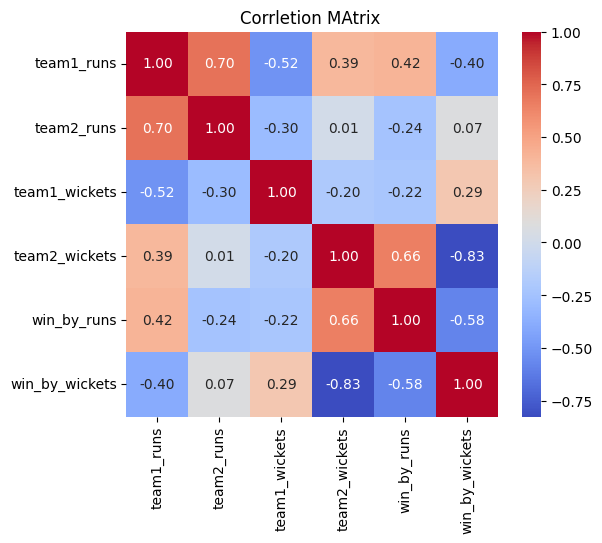

In [65]:
import seaborn as sns

corr = X.corr()
plt.figure(figsize=(6,5))

sns.heatmap(
    corr,annot=True,cmap='coolwarm',fmt='.2f'
)
plt.title('Corrletion MAtrix ')
plt.show()

In [67]:
scaler = StandardScaler()
x_scale = scaler.fit_transform(X)
x_scale[:5]

array([[-1.48275466, -0.93490489, -0.57237672, -0.70387888, -0.61995945,
         0.91096577],
       [-0.22132228,  0.25143488, -0.57237672,  0.02688081, -0.61995945,
         0.29356145],
       [ 0.54650613,  0.99934474, -1.95436525, -0.33849904, -0.61995945,
         0.60226361],
       [-0.7423487 , -0.21278503, -0.11171388, -0.33849904, -0.61995945,
         0.60226361],
       [ 0.68361834, -0.52226497, -0.11171388,  0.39226065,  1.84479499,
        -0.94124718]])

In [70]:
x_scale.mean().round(2)

np.float64(-0.0)

In [71]:
x_scale.std()

np.float64(1.0)

In [73]:
# Apply PCA

pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scale)

pca_df = pd.DataFrame(
    x_pca,
    columns=(['PC1','PC2'])
)

pca_df.head()

,PC1,PC2
0,-1.673264,-0.488633
1,-0.280574,0.528715
2,0.283096,1.992024
3,-1.058970,0.008845
4,1.732323,-0.964595


In [74]:
variance = pca.explained_variance_ratio_

print(f'PC1:{variance[0]*100:.2f}%')
print(f'PC2:{variance[1]*100:.2f}%')

print(f'Total Information Retained :{round(variance.sum()*100,2)}%')

PC1:48.10%
PC2:28.64%
Total Information Retained :76.74%


In [76]:
variance


array([0.48097855, 0.28637271])

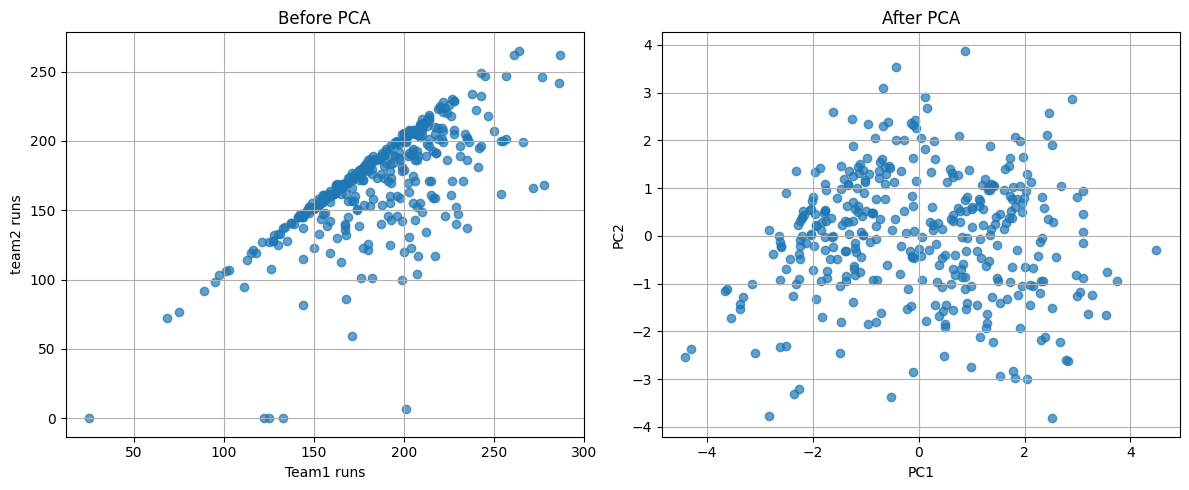

In [77]:
# Before PCA

plt.figure(figsize=(12,5))

plt.subplot(121)

plt.scatter(
    X['team1_runs'],
    X['team2_runs'],
    alpha=0.7
)

plt.xlabel('Team1 runs')
plt.ylabel('team2 runs')

plt.title('Before PCA')
plt.grid(True)



plt.subplot(122)

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    alpha=0.7
)

plt.xlabel('PC1')
plt.ylabel('PC2')

plt.title('After PCA')
plt.grid(True)

plt.tight_layout()

plt.show()


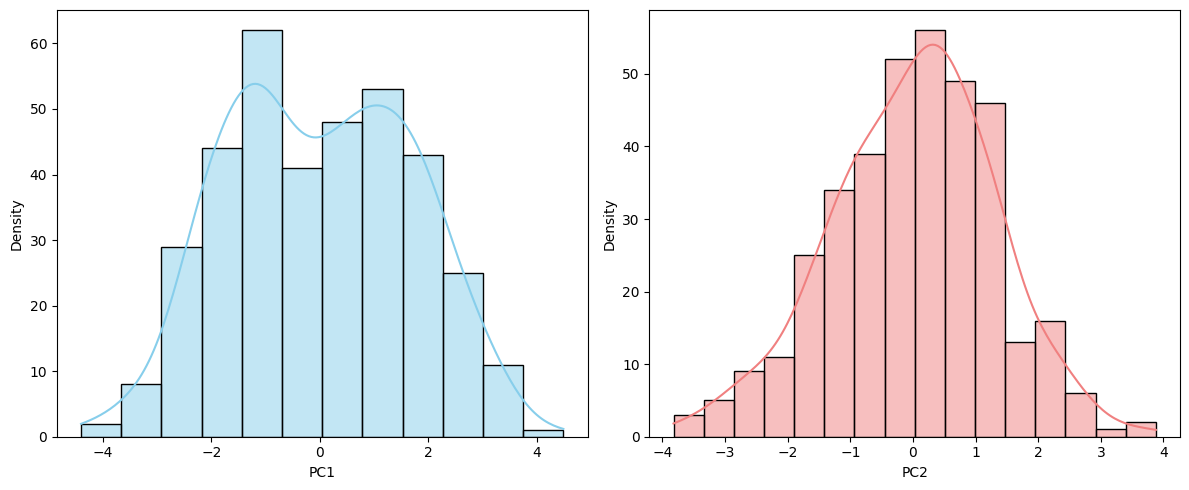

In [78]:


plt.figure(figsize=(12,5))

plt.subplot(121)
sns.histplot(pca_df['PC1'],kde=True,color='skyblue')
plt.xlabel('PC1')
plt.ylabel('Density')

plt.subplot(122)
sns.histplot(pca_df['PC2'],kde=True,color='lightcoral')
plt.xlabel('PC2')
plt.ylabel('Density')

plt.tight_layout()
plt.show()